# Week 3 — Random Forest Model
### Modeling Disagreement in LLM Harm Annotation

---

**Research Question:** Given all the information about a prompt and an annotator, can we predict the harmfulness rating this annotator will assign to the prompt?

**Why Random Forest?**
Our linear regression models achieved R² ≈ 0.257, which is low. Linear regression assumes a straight-line relationship between features and ratings. But human judgment is non-linear — a Random Forest can capture these complex patterns.

**How Random Forest works:**
- Builds 100 different decision trees
- Each tree sees a slightly different random subset of data and features
- Final prediction = average of all 100 trees
- This reduces overfitting and captures non-linear relationships


## 0. Setup

In [1]:
import sys, os, warnings
warnings.filterwarnings('ignore')

def find_repo_root():
    current = os.path.abspath(os.getcwd())
    for _ in range(5):
        if os.path.exists(os.path.join(current, 'data', 'annotations.csv')):
            return current
        current = os.path.dirname(current)
    raise FileNotFoundError("Cannot find repo root.")

REPO_ROOT = find_repo_root()
sys.path.insert(0, os.path.join(REPO_ROOT, 'src'))
os.chdir(REPO_ROOT)
os.makedirs("outputs", exist_ok=True)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import train_test_split
from data_loader import load_data, get_rating_columns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 110

print("All libraries loaded successfully.")

All libraries loaded successfully.


## 1. Load & Prepare Data

Same data preparation as before:
1. Load annotations and prompts
2. Convert to long format (100 annotators × 150 prompts = 15,000 rows)
3. Encode categorical variables


In [2]:
annotations, prompts = load_data()
rating_cols = get_rating_columns(annotations)

# Feature groups
demo_cols       = ['Gender', 'Age', 'Political_Affiliation', 'Education']
factor_cols     = ['Factor_1', 'Factor_2', 'Factor_3']
value_cols      = [c for c in prompts.columns if c.startswith('value_topic_')]
prompt_num_cols = ['Harm_Level'] + value_cols

# Convert to long format
rows = []
for _, ann_row in annotations.iterrows():
    for col in rating_cols:
        q_idx  = int(col.replace('Rating_', ''))
        rating = ann_row[col]
        if pd.isna(rating):
            continue
        prompt_row = prompts[prompts['Question_Index'] == q_idx]
        if len(prompt_row) == 0:
            continue
        row = {'rating': rating, 'Participant_ID': ann_row['Participant_ID']}
        for c in demo_cols + factor_cols:
            row[c] = ann_row[c]
        for c in prompt_num_cols:
            row[c] = prompt_row[c].values[0]
        rows.append(row)

long_df = pd.DataFrame(rows)

# Encode categorical variables
long_df_encoded = pd.get_dummies(long_df, columns=demo_cols, drop_first=True)

# Define X and y
y            = long_df_encoded['rating']
feature_cols = [c for c in long_df_encoded.columns
                if c not in ['rating', 'Participant_ID']]
X            = long_df_encoded[feature_cols]

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Long format : {long_df.shape[0]:,} rows x {long_df.shape[1]} columns")
print(f"Training set: {X_train.shape[0]:,} rows")
print(f"Test set    : {X_test.shape[0]:,} rows")
print(f"Features    : {len(feature_cols)}")

Long format : 14,725 rows x 49 columns
Training set: 11,780 rows
Test set    : 2,945 rows
Features    : 58


## 2. Baseline — Linear Regression

We first run linear regression as a baseline to compare against Random Forest.


In [3]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
pred_lr  = lr_model.predict(X_test)
r2_lr    = r2_score(y_test, pred_lr)
rmse_lr  = np.sqrt(mean_squared_error(y_test, pred_lr))

print(f"Linear Regression (baseline):")
print(f"  R²   = {r2_lr:.3f}")
print(f"  RMSE = {rmse_lr:.2f}")

Linear Regression (baseline):
  R²   = 0.257
  RMSE = 32.42


## 3. Random Forest Model

**Key parameters:**
- `n_estimators=100` — build 100 decision trees
- `max_depth=10` — each tree can have at most 10 levels of splits
- `random_state=42` — ensures reproducibility
- `n_jobs=-1` — use all available CPU cores (faster training)


In [4]:
print("Training Random Forest... (may take 1-2 minutes)")

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
pred_rf  = rf_model.predict(X_test)
r2_rf    = r2_score(y_test, pred_rf)
rmse_rf  = np.sqrt(mean_squared_error(y_test, pred_rf))

print(f"\nRandom Forest:")
print(f"  R²   = {r2_rf:.3f}  → explains {r2_rf*100:.1f}% of variance")
print(f"  RMSE = {rmse_rf:.2f} → off by {rmse_rf:.1f} points on average")

Training Random Forest... (may take 1-2 minutes)

Random Forest:
  R²   = 0.404  → explains 40.4% of variance
  RMSE = 29.04 → off by 29.0 points on average


## 4. Comparison: Linear Regression vs Random Forest


            Model       R²      RMSE
Linear Regression 0.257141 32.416609
    Random Forest 0.404005 29.035926

R² improvement: +57.1%


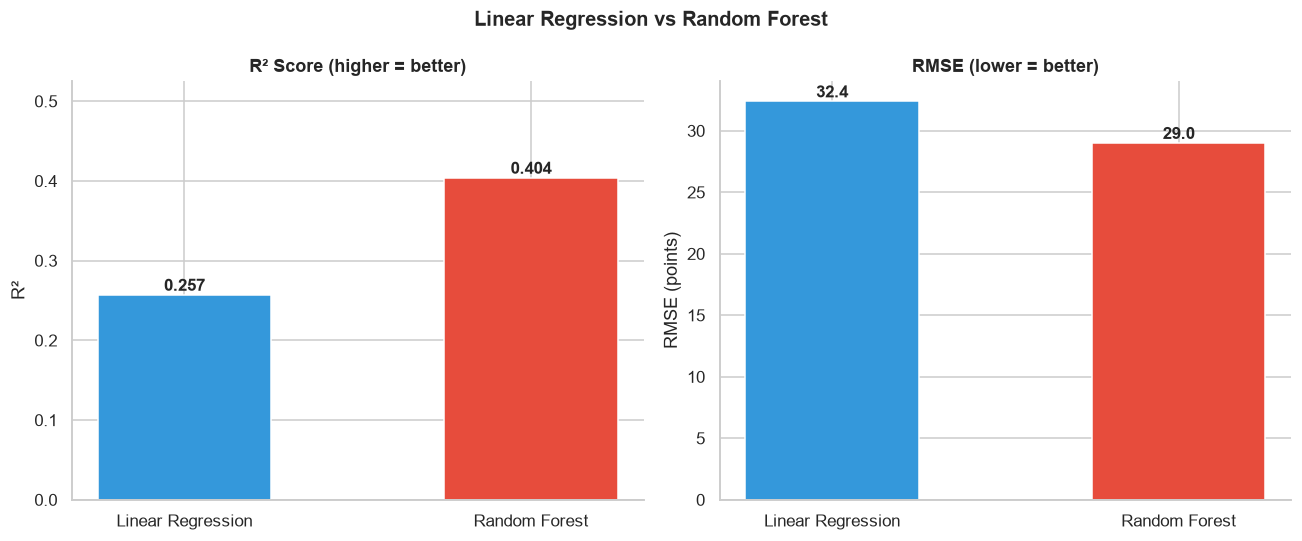

Saved: outputs/fig_rf_comparison.png


In [5]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'R²'   : [r2_lr, r2_rf],
    'RMSE' : [rmse_lr, rmse_rf],
})

print(results.to_string(index=False))
print()
improvement = (r2_rf - r2_lr) / r2_lr * 100
print(f"R² improvement: +{improvement:.1f}%")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
colors = ['#3498db', '#e74c3c']

axes[0].bar(results['Model'], results['R²'], color=colors, edgecolor='white', width=0.5)
axes[0].set_title('R² Score (higher = better)', fontweight='bold')
axes[0].set_ylabel('R²')
axes[0].set_ylim(0, max(results['R²']) * 1.3)
for i, v in enumerate(results['R²']):
    axes[0].text(i, v + 0.005, f'{v:.3f}', ha='center', fontsize=11, fontweight='bold')
axes[0].spines[['top', 'right']].set_visible(False)

axes[1].bar(results['Model'], results['RMSE'], color=colors, edgecolor='white', width=0.5)
axes[1].set_title('RMSE (lower = better)', fontweight='bold')
axes[1].set_ylabel('RMSE (points)')
for i, v in enumerate(results['RMSE']):
    axes[1].text(i, v + 0.3, f'{v:.1f}', ha='center', fontsize=11, fontweight='bold')
axes[1].spines[['top', 'right']].set_visible(False)

fig.suptitle('Linear Regression vs Random Forest', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("outputs/fig_rf_comparison.png", bbox_inches='tight')
plt.show()
print("Saved: outputs/fig_rf_comparison.png")

## 5. Feature Importance

One advantage of Random Forest over linear regression:
it gives us **feature importance** scores.

This tells us: **which features does the model rely on most?**

Unlike linear regression coefficients, feature importance is always positive
and sums to 1.0. Higher = more important for predictions.


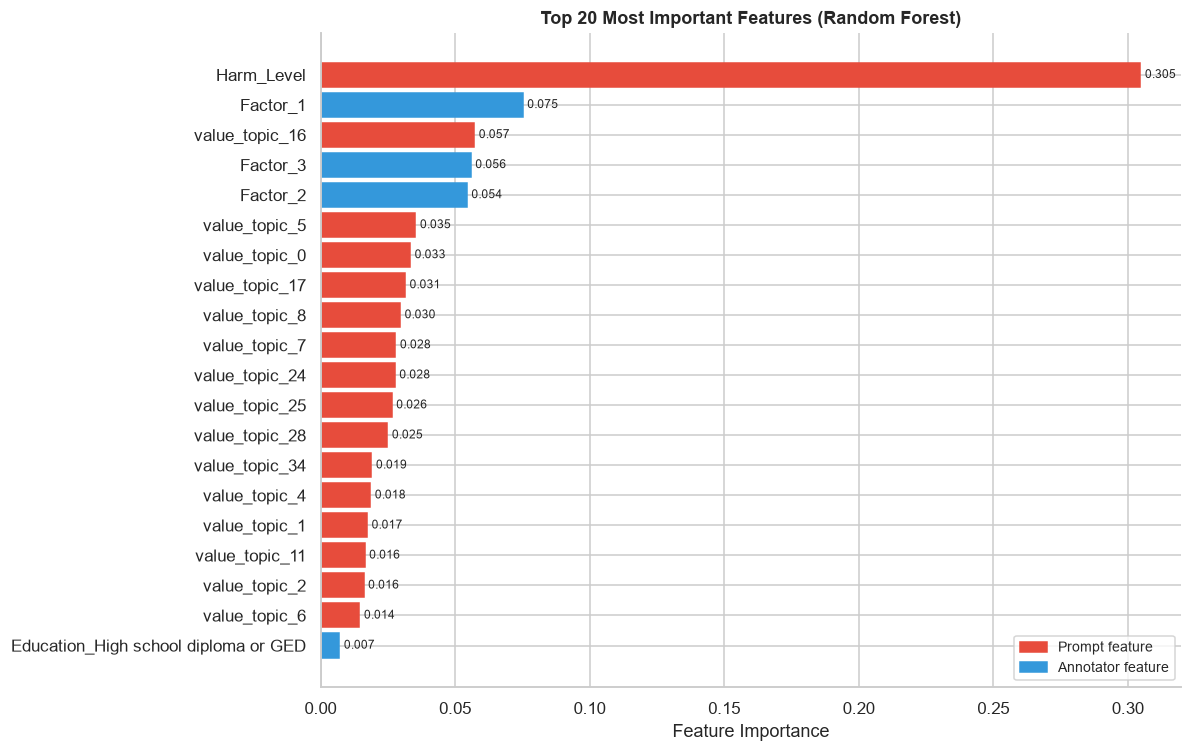

Saved: outputs/fig_rf_importance.png


In [6]:
importance_df = pd.DataFrame({
    'feature'   : feature_cols,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False).head(20)

fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(
    importance_df['feature'][::-1],
    importance_df['importance'][::-1],
    color=sns.color_palette("muted")[0],
    edgecolor='white'
)
ax.set_title('Top 20 Most Important Features (Random Forest)',
             fontweight='bold', fontsize=12)
ax.set_xlabel('Feature Importance')
ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=8)
ax.spines[['top', 'right']].set_visible(False)

# Color prompt vs annotator features differently
prompt_feat  = set(prompt_num_cols)
colors_feat  = ['#e74c3c' if f in prompt_feat else '#3498db'
                for f in importance_df['feature'][::-1]]
for bar, color in zip(ax.patches, colors_feat):
    bar.set_color(color)

from matplotlib.patches import Patch
legend = [Patch(color='#e74c3c', label='Prompt feature'),
          Patch(color='#3498db', label='Annotator feature')]
ax.legend(handles=legend, fontsize=9)

plt.tight_layout()
plt.savefig("outputs/fig_rf_importance.png", bbox_inches='tight')
plt.show()
print("Saved: outputs/fig_rf_importance.png")

In [8]:
print("Output files generated:")
for f in sorted(os.listdir("outputs")):
    if f.endswith('.png') and 'rf' in f or 'actual' in f:
        size = os.path.getsize(os.path.join("outputs", f)) / 1024
        print(f"  {f:<50} ({size:.1f} KB)")

Output files generated:
  fig_actual_vs_predicted.png                        (198.7 KB)
  fig_rf_comparison.png                              (34.5 KB)
  fig_rf_importance.png                              (66.6 KB)
